<a href="https://colab.research.google.com/github/ProNob4/CodeAlpha_ProjectPronob/blob/main/Unemployment_Analysis_with_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

# Your Google Drive shared link
share_link = "https://drive.google.com/file/d/1wDPHCKb0h6vcS5ygqzkEPVZqcmTd_3Qy/view?usp=sharing"

# Extract the file ID from the link
file_id = share_link.split('/d/')[1].split('/')[0]

# Create a direct download link
direct_download_url = f"https://drive.google.com/uc?export=download&id={file_id}"

try:
    # Read the CSV directly into a pandas DataFrame
    df = pd.read_csv(direct_download_url)
    print("File successfully loaded from Google Drive!")
    print(df.head())
except Exception as e:
    print("An error occurred while loading the file:", e)
    print("If this fails, ensure that the file link has 'Anyone with the link' viewer access in Google Drive.")

File successfully loaded from Google Drive!
           Region         Date  Frequency   Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-01-2020          M                              5.48   
1  Andhra Pradesh   29-02-2020          M                              5.83   
2  Andhra Pradesh   31-03-2020          M                              5.79   
3  Andhra Pradesh   30-04-2020          M                             20.51   
4  Andhra Pradesh   31-05-2020          M                             17.43   

    Estimated Employed   Estimated Labour Participation Rate (%) Region.1  \
0             16635535                                     41.02    South   
1             16545652                                     40.90    South   
2             15881197                                     39.18    South   
3             11336911                                     33.10    South   
4             12988845                                     36.46    South   

   longitude  lati

Data Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   267 non-null    object        
 1   Date                                     267 non-null    datetime64[ns]
 2   Frequency                                267 non-null    object        
 3   Estimated Unemployment Rate (%)          267 non-null    float64       
 4   Estimated Employed                       267 non-null    int64         
 5   Estimated Labour Participation Rate (%)  267 non-null    float64       
 6   Region.1                                 267 non-null    object        
 7   longitude                                267 non-null    float64       
 8   latitude                                 267 non-null    float64       
dtypes: datetime64[ns](1), float64(

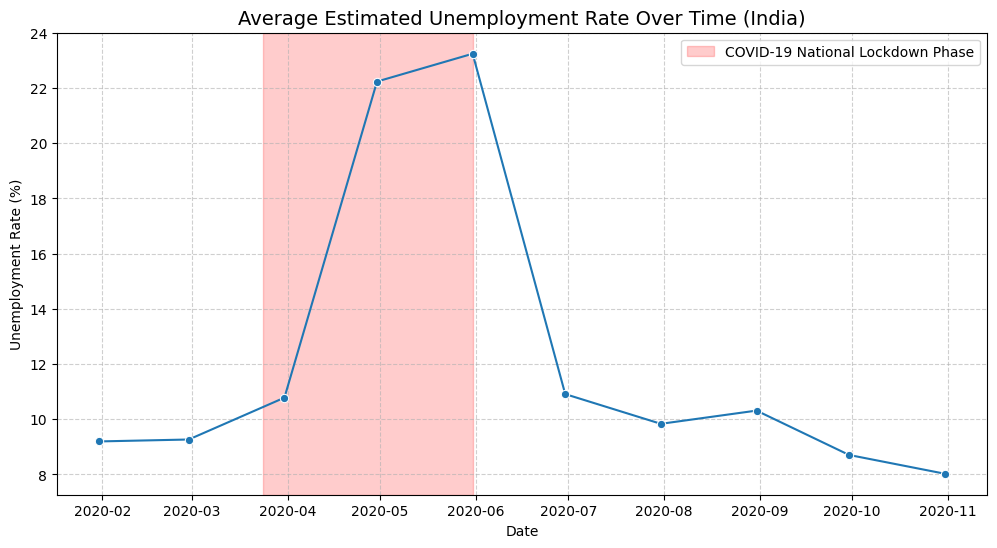

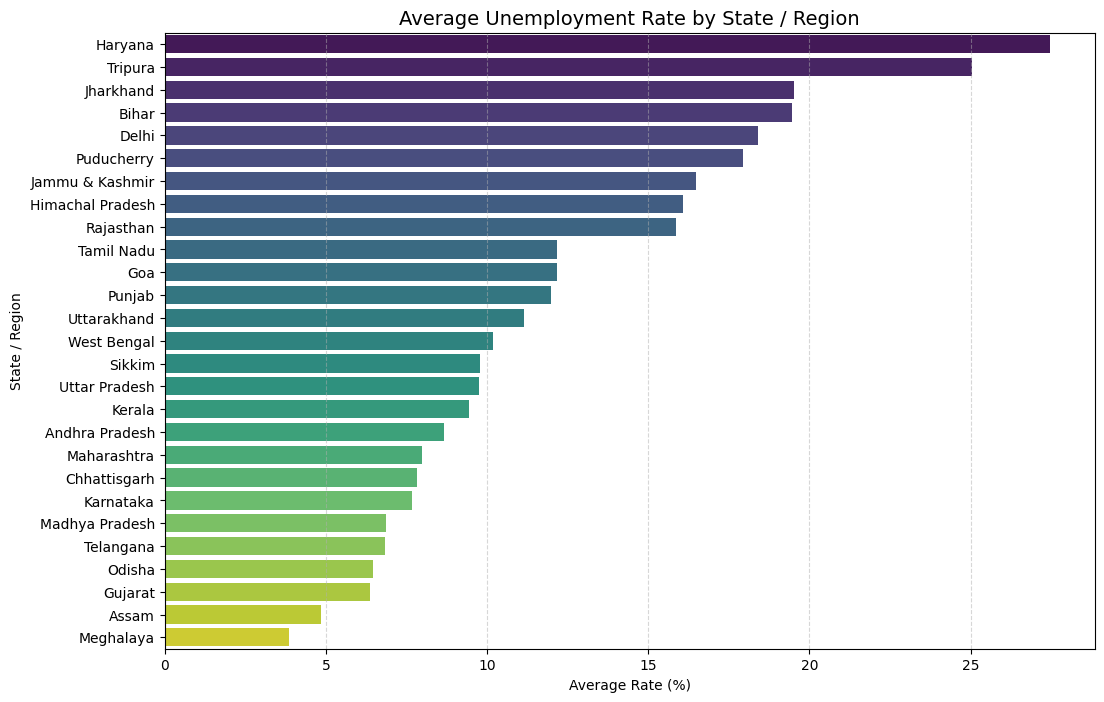

In [3]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Clean column headers and format dates
# We strip potential whitespaces in column names
df.columns = df.columns.str.strip()

if 'Date' in df.columns:
    # Use dayfirst=True to correctly parse the dates formatted as DD-MM-YYYY
    df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

print("Data Summary:")
print(df.info())
print(df.head())

# 3. Trend Analysis Across Time (Average Unemployment Rate across all regions)
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='Date', y='Estimated Unemployment Rate (%)', marker='o', errorbar=None)
plt.axvspan(pd.Timestamp('2020-03-24'), pd.Timestamp('2020-05-31'), color='red', alpha=0.2, label='COVID-19 National Lockdown Phase')
plt.title("Average Estimated Unemployment Rate Over Time (India)", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 4. Regional Comparison
if 'Region' in df.columns and df['Region'].nunique() > 1:
    plt.figure(figsize=(12, 8))
    region_avg = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().sort_values(ascending=False)
    sns.barplot(x=region_avg.values, y=region_avg.index, palette='viridis', hue=region_avg.index, legend=False)
    plt.title("Average Unemployment Rate by State / Region", fontsize=14)
    plt.xlabel("Average Rate (%)")
    plt.ylabel("State / Region")
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.show()